> Версия для GitHub. Эксперимент с `min_df` встроен в раздел 1.4а: его таблицы и графики сохранены после выполнения. Старые выводы остальных разделов очищены; полная лабораторная заново не запускалась. Исходные тексты находятся в локальном CSV, исключённом из Git.

# Классификация текстов фанфиков по вселенной Гарри Поттера

Выполнила: Кротова Ксения РИС-24-1

В работе на собственном корпусе фанфиков с Фикбука:

- описывается состав собранных данных и выбирается выборка для классификации;
- тексты токенизируются и очищаются, выполняются стемминг и лемматизация;
- тексты представляются числовыми признаками с помощью Bag of Words, TF-IDF, Word2Vec и частеречной разметки;
- обучаются три модели бинарной классификации;
- качество моделей сравнивается по Accuracy, Precision, Recall, F1 и ROC-кривым;
- обсуждаются результаты и ограничения исследования.

## Подготовка среды

Устанавливаем и подключаем библиотеки. Эти ячейки выполняются перед загрузкой данных.

In [ ]:
# Зависимости: python -m pip install -r requirements.txt


In [ ]:
# Зависимости: python -m pip install -r requirements.txt


In [ ]:
# Зависимости: python -m pip install -r requirements.txt


In [ ]:
# Зависимости: python -m pip install -r requirements.txt


In [ ]:
# 0. Библиотеки и настройки

import re
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.stem.snowball import RussianStemmer
from stop_words import get_stop_words
import pymorphy3
from gensim.models import Word2Vec

from sklearn.feature_extraction.text import (
    CountVectorizer, TfidfVectorizer, HashingVectorizer
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score
)
stemmer = RussianStemmer()
SEED = 42
np.random.seed(SEED)

## 0. Данные и первичный обзор

### 0.1. Загрузка данных

Загружаем CSV с собранными работами и проверяем, что файл прочитан.

In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
df_all = pd.read_csv(ROOT / "ficbook_all_collected_1900.csv")
print("Загружено работ:", len(df_all))


### 0.2. Первичный просмотр корпуса

Проверяем размер таблицы, названия полей и первые строки.

In [ ]:
print("Размер таблицы:", df_all.shape)
print("\nНазвания столбцов:")
print(df_all.columns.tolist())

print("\nИсточники сбора:")
print(df_all["source_group"].value_counts())

print("\nРабот по Гарри Поттеру:", df_all["hp_eligible"].sum())
print("Работ с текстом:", df_all["text"].notna().sum())
print("Работ со значком перевода:", df_all["translation_badge_present"].sum())

df_all.head(10)

### 0.3. Состав корпуса и описательная статистика

Описываем поля, распределения и пропуски до подготовки текстов.

In [ ]:
df_all["likes_num"] = pd.to_numeric(df_all["likes"], errors="coerce")
df_all["work_words_num"] = pd.to_numeric(
    df_all["words_reported"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

overview = df_all.groupby("source_group").agg(
    работ=("story_id", "size"),
    работ_HP=("hp_eligible", "sum"),
    с_текстом=("fragment_available", "sum"),
    переводов_со_значком=("translation_badge_present", "sum"),
    медиана_лайков=("likes_num", "median"),
    медиана_слов_в_работе=("work_words_num", "median"),
    медиана_слов_в_фрагменте=("fragment_word_count", "median")
)

display(overview.round(1))

print("Уникальных ID:", df_all["story_id"].nunique())
print("Без текста:", df_all["text"].isna().sum())
print("\nПропуски в основных полях:")
display(df_all[[
    "author_url", "likes", "words_reported",
    "date_published_adapter", "tags", "pairing", "text"
]].isna().sum().to_frame("Пропусков"))

#### Что означает каждый столбец

In [ ]:
# 4. Словарь данных

descriptions = {
    "story_id": "Уникальный ID работы на Фикбуке",
    "source_platform": "Площадка, с которой получена работа",
    "source_group": "Часть каталога: обычная, «Популярные» или платные «Горячие»",
    "source_url": "Ссылка на работу",
    "catalog_url": "Страница каталога, где работа была найдена",
    "metadata_retrieved_at_utc": "Когда собраны данные карточки",
    "title": "Название работы",
    "author": "Имя автора в карточке",
    "author_url": "Ссылка на страницу автора",
    "fandom": "Фандом, указанный в карточке",
    "language": "Язык, указанный в карточке",
    "work_type_hint": "Предполагаемый тип публикации",
    "hp_eligible": "Включена ли работа в проверенную HP-выборку",
    "hp_evidence_field": "По какому полю подтверждена связь с Гарри Поттером",
    "translation_badge_present": "Есть ли явный значок «Перевод»",
    "translation_status_note": "Как установлен статус перевода; отсутствие значка не доказывает оригинальность",
    "chapters": "Число глав по карточке",
    "words_reported": "Длина всей работы в словах по карточке",
    "date_published_adapter": "Дата первой главы по адаптеру",
    "date_updated_adapter": "Дата последнего обновления по адаптеру",
    "status": "Завершена работа или ещё пишется",
    "rating": "Возрастной рейтинг",
    "direction": "Направленность работы",
    "pairing": "Персонажи и пейринги из карточки",
    "tags": "Метки автора в карточке",
    "likes": "Лайки на момент сбора",
    "label_romance_tag": "Есть ли буквальная метка «Романтика»",
    "label_angst_tag": "Есть ли буквальная метка «Ангст»",
    "label_humor_tag": "Есть ли буквальная метка «Юмор»",
    "label_crossover_tag": "Есть ли буквальная метка «Кроссовер»",
    "fragment_available": "Удалось ли сохранить текстовый фрагмент",
    "fragment_word_count": "Число слов в сохранённом фрагменте",
    "fragment_sha256": "Контрольный хеш фрагмента",
    "fragment_method": "Способ получения фрагмента",
    "fragment_retrieved_at_utc": "Когда получен фрагмент",
    "text": "Начало первой главы, максимум 500 слов"
}

dictionary = pd.DataFrame({
    "Столбец": df_all.columns,
    "Что означает": [descriptions.get(col, "Производный столбец для анализа")
                     for col in df_all.columns],
    "Заполнено": [df_all[col].notna().sum() for col in df_all.columns]
})

display(dictionary)

#### Описательные статистики

In [ ]:
# 5. Описательные статистики

hp = df_all[df_all["hp_eligible"]].copy()

hp["likes_num"] = pd.to_numeric(hp["likes"], errors="coerce")
hp["work_words_num"] = pd.to_numeric(
    hp["words_reported"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

stats = hp.groupby("source_group").agg(
    работ=("story_id", "size"),
    уникальных_авторов=("author_url", "nunique"),
    с_текстом=("fragment_available", "sum"),
    переводов_со_значком=("translation_badge_present", "sum"),
    романтика=("label_romance_tag", "sum"),
    ангст=("label_angst_tag", "sum"),
    юмор=("label_humor_tag", "sum"),
    кроссовер=("label_crossover_tag", "sum"),
    лайки_медиана=("likes_num", "median"),
    лайки_10_процентиль=("likes_num", lambda x: x.quantile(0.10)),
    лайки_90_процентиль=("likes_num", lambda x: x.quantile(0.90)),
    слов_в_работе_медиана=("work_words_num", "median"),
    слов_во_фрагменте_медиана=("fragment_word_count", "median")
)

display(stats.round(1))

#### Состав выборки: жанры, авторы и переводы

In [ ]:
# 6. Визуализация состава HP-корпуса

hp = df_all[df_all["hp_eligible"]].copy()
ordinary = hp[hp["source_group"] == "ordinary_catalog"].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Доля работ с каждой меткой в обычном каталоге
tag_columns = {
    "Романтика": "label_romance_tag",
    "Ангст": "label_angst_tag",
    "Юмор": "label_humor_tag",
    "Кроссовер": "label_crossover_tag"
}
tag_shares = pd.Series({
    name: ordinary[col].mean() * 100
    for name, col in tag_columns.items()
})
tag_shares.plot.bar(ax=axes[0], color="#6B83B5")
axes[0].set_title(f"Метки: обычный каталог (n={len(ordinary)})")
axes[0].set_ylabel("Доля работ, %")
axes[0].tick_params(axis="x", rotation=35)

# 2. Работы с явным значком перевода и без него
translation_counts = pd.crosstab(
    hp["source_group"],
    hp["translation_badge_present"]
).reindex(columns=[False, True], fill_value=0)
translation_counts.columns = ["Без значка", "Со значком «Перевод»"]
translation_counts.plot.bar(
    ax=axes[1], color=["#78A99A", "#D19A6C"]
)
axes[1].set_title("Статус перевода по источникам")
axes[1].set_ylabel("Число работ")
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend(fontsize=8)

# 3. Уникальные авторы в обычном каталоге
author_counts = ordinary.groupby("translation_badge_present")[
    "author_url"
].nunique().reindex([False, True], fill_value=0)
author_counts.index = ["Без значка", "Со значком «Перевод»"]
author_counts.plot.bar(
    ax=axes[2], color=["#78A99A", "#D19A6C"]
)
axes[2].set_title("Уникальные авторы: обычный каталог")
axes[2].set_ylabel("Число авторов")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

#### Пропуски и их смысл

In [ ]:
# 7. Пропуски в полях HP-корпуса

hp = df_all[df_all["hp_eligible"]].copy()

columns_to_check = [
    "text", "author_url", "likes", "words_reported",
    "date_published_adapter", "tags", "pairing",
    "direction", "status", "rating"
]

missing = pd.DataFrame({
    "Пропусков": hp[columns_to_check].isna().sum(),
    "Доля, %": hp[columns_to_check].isna().mean().mul(100).round(1)
}).sort_values("Пропусков", ascending=False)

display(missing)

У 31% работ не указана направленность. Для нашей задачи она не нужна: модель смотрит только на текст, поэтому эти работы мы оставляем.

## Часть 1. Подготовка текстов и базовая классификация

Здесь выполняем пункты 1.1–1.5 задания на собственном корпусе.

### 1.1. Предобработка текстов

Работаем с выбранными фрагментами всех подходящих произведений о Гарри Поттере.

#### Отбор работ и проверка текстов

In [ ]:
# 1.1. Отбираем все собранные HP-работы с текстом

hp = df_all[
    df_all["hp_eligible"] & df_all["text"].notna()
].copy()

print("Взято работ:", len(hp))
print("\nПо источникам:")
print(hp["source_group"].value_counts())
print("\nСо значком перевода:", hp["translation_badge_present"].sum())
print("Без значка перевода:", (~hp["translation_badge_present"]).sum())

#### Токенизация: NLTK и сравнение с другими вариантами

In [ ]:
# 1.1. Токенизация с помощью NLTK

from nltk.tokenize import wordpunct_tokenize

hp["tokens"] = hp["text"].map(wordpunct_tokenize)

print("Обработано текстов:", len(hp))
print("Токенов в первом тексте:", len(hp["tokens"].iloc[0]))
print("Первые 20 токенов:", hp["tokens"].iloc[0][:20])

In [ ]:
from nltk.tokenize import wordpunct_tokenize
from razdel import tokenize as razdel_tokenize
from tokenizers import ByteLevelBPETokenizer
import spacy

example = hp["text"].iloc[0][:300]
print("Исходный фрагмент:\n", example)

# Для токенизации spaCy достаточно правил русского языка — модель скачивать не нужно.
nlp_ru = spacy.blank("ru")

# Маленький учебный BPE: обучаем только для демонстрации различия токенов.
bpe = ByteLevelBPETokenizer()
bpe.train_from_iterator(
    hp["text"].head(200).tolist(),
    vocab_size=1000,
    min_frequency=2
)

variants = {
    "NLTK": wordpunct_tokenize(example),
    "Razdel": [token.text for token in razdel_tokenize(example)],
    "spaCy": [token.text for token in nlp_ru(example)],
    "BPE": bpe.encode(example).tokens,
}

for name, tokens in variants.items():
    print(f"\n{name}: {len(tokens)} токенов")
    print(tokens[:25])

In [ ]:
print(bpe.decode(bpe.encode(example).ids) == example)

#### Сколько токенов получилось

In [ ]:
hp["n_tokens"] = hp["tokens"].map(len)

print(hp["n_tokens"].describe())

#### Нижний регистр и удаление знаков препинания

In [ ]:
# 1.1. Приводим токены к нижнему регистру

hp["tokens_lower"] = hp["tokens"].map(
    lambda tokens: [token.lower() for token in tokens]
)

print("До:   ", hp["tokens"].iloc[0][:15])
print("После:", hp["tokens_lower"].iloc[0][:15])

In [ ]:
# 1.1. Удаляем пунктуацию и специальные символы

hp["tokens_words"] = hp["tokens_lower"].map(
    lambda tokens: [token for token in tokens if token.isalpha()]
)

print("До:   ", hp["tokens_lower"].iloc[0][:20])
print("После:", hp["tokens_words"].iloc[0][:20])
print("Медиана токенов после удаления знаков:",
      hp["tokens_words"].map(len).median())

#### Стоп-слова: сравнение списков и выбор для задачи

In [ ]:
# Сравнение русских списков стоп-слов

import nltk
from nltk.corpus import stopwords
from spacy.lang.ru.stop_words import STOP_WORDS as SPACY_RU_STOP_WORDS

nltk.download("stopwords", quiet=True)

stop_lists = {
    "stop-words": set(get_stop_words("ru")),
    "NLTK": set(stopwords.words("russian")),
    "spaCy": set(SPACY_RU_STOP_WORDS),
}

print("Размер списков:")
for name, words in stop_lists.items():
    print(f"{name}: {len(words)} слов")

important_words = [
    "и", "в", "не", "нет", "никогда",
    "я", "мы", "он", "она",
    "любовь", "гарри", "гермиона"
]

comparison = pd.DataFrame({
    name: [word in words for word in important_words]
    for name, words in stop_lists.items()
}, index=important_words)

display(comparison)

In [ ]:
# Полные списки стоп-слов рядом друг с другом

stop_table = pd.DataFrame({
    name: pd.Series(sorted(words))
    for name, words in stop_lists.items()
}).fillna("")

with pd.option_context("display.max_rows", None):
    display(stop_table)

In [ ]:
# Выбираем список, но пока не удаляем слова из текстов

keep_words = {
    "не", "нет", "ни", "никогда",
    "я", "мы", "ты", "вы", "он", "она", "они"
}

stop_words_ru = stop_lists["NLTK"] - keep_words

print("Стоп-слов после настройки:", len(stop_words_ru))
print("Сохраняем:", sorted(keep_words))
print("Примеры удаляемых слов:", sorted(stop_words_ru)[:30])

# Для воспроизводимости фиксируем список именно из исходного запуска.
from fanfic_lab6.preprocessing import STOP_WORDS
stop_words_ru = set(STOP_WORDS)


In [ ]:
# 1.1. Удаление стоп-слов

hp["tokens_no_stop"] = hp["tokens_words"].map(
    lambda tokens: [word for word in tokens if word not in stop_words_ru]
)

print("До:   ", hp["tokens_words"].iloc[0][:25])
print("После:", hp["tokens_no_stop"].iloc[0][:25])
print(
    "Медиана слов после удаления:",
    hp["tokens_no_stop"].map(len).median()
)

#### Стемминг: сравнение реализаций и защита слов мира Гарри Поттера

In [ ]:
import snowballstemmer

snowball_ru = snowballstemmer.stemmer("russian")
words = ["гарри", "гермиона", "книгой", "любила", "хогвартсе"]

display(pd.DataFrame({
    "Слово": words,
    "NLTK": [stemmer.stem(word) for word in words],
    "snowballstemmer": [snowball_ru.stemWord(word) for word in words]
}))

In [ ]:
# Слова мира Гарри Поттера, которые хотим сохранить целыми
protected_terms = {
    # Персонажи и фамилии
    "гарри", "поттер", "гермиона", "грейнджер", "рон", "уизли",
    "драко", "малфой", "люциус", "нарцисса", "снейп", "северус",
    "дамблдор", "альбус", "волдеморт", "том", "реддл",
    "сириус", "блэк", "ремус", "люпин", "джинни", "луна",
    "невилл", "лонгботтом", "беллатриса", "лестрейндж",
    "хагрид", "минерва", "макгонагалл", "фред", "джордж",
    "лили", "джеймс", "седрик", "добби", "квиррелл",
    "дурсль",

    # Места, факультеты, организации
    "хогвартс", "хогсмид", "азкабан", "гринготтс",
    "гриффиндор", "слизерин", "когтевран", "пуффендуй",
    "дурмстранг", "шармбатон", "гриммо",

    # Предметы и понятия
    "квиддич", "крестраж", "дементор", "анимаг",
    "маггл", "сквиб", "патронус", "омут", "маховик",
    "метла", "мантия",

    # Заклинания
    "экспеллиармус", "люмос", "нокc", "акцио",
    "авада", "кедавра", "империо", "круцио",
    "алохомора", "обливиэйт", "протего", "репаро",
    "ступефай", "редукто", "сектумсемпра",
    "левиоса", "экспекто", "инсендио", "диффиндо",
}

# Начальная форма остаётся без обрезания
special_forms = {word: word for word in protected_terms}

# Частые падежные формы приводим к одной записи
special_forms.update({
    "гермионы": "гермиона",
    "гермионе": "гермиона",
    "гермиону": "гермиона",
    "гермионой": "гермиона",


    "рона": "рон",
    "рону": "рон",
    "роном": "рон",

    "снейпа": "снейп",
    "снейпу": "снейп",
    "снейпом": "снейп",

    "малфоя": "малфой",
    "малфою": "малфой",
    "малфоем": "малфой",

    "хогвартса": "хогвартс",
    "хогвартсу": "хогвартс",
    "хогвартсом": "хогвартс",
    "хогвартсе": "хогвартс",

    "азкабана": "азкабан",
    "азкабане": "азкабан",

    "дамблдора": "дамблдор",
    "дамблдору": "дамблдор",
    "волдеморта": "волдеморт",
    "волдеморту": "волдеморт",

    "патронуса": "патронус",
    "крестража": "крестраж",
    "крестражи": "крестраж",
    "дементора": "дементор",
    "дементоры": "дементор",

    "кедавры": "кедавра",

    "персиваля": "персиваль",
    "дурслей": "дурсль",
    "дурсли": "дурсль",
})

def stem_with_exceptions(word):
    return special_forms.get(word, stemmer.stem(word))

print("Защищено начальных форм:", len(protected_terms))
print("Всего форм в словаре:", len(special_forms))

#### Проверка обработки на реальных фрагментах

In [ ]:
idx = hp.index[hp["tokens_no_stop"].map(len).ge(200)][0]
original = hp.loc[idx, "text"][:900].rsplit(" ", 1)[0]
sample_tokens = hp.loc[idx, "tokens_no_stop"]

In [ ]:
# Для таблицы «исходный текст / после»
words = [w.lower() for w in wordpunct_tokenize(original) if w.isalpha()]
words = [w for w in words if w not in stop_words_ru]
tokens = [stem_with_exceptions(w) for w in words]

# Для длинной таблицы сравнения стемминга
comparison = pd.DataFrame({
    "Исходное слово": sample_tokens,
    "Обычный NLTK": [stemmer.stem(w) for w in sample_tokens],
    "С защитой имён": [stem_with_exceptions(w) for w in sample_tokens],
})

print("Малфой в итоговом тексте:", [w for w in tokens if w.startswith("малф")])

In [ ]:
with pd.option_context(
    "display.max_rows", 200,
    "display.min_rows", 200,
    "display.max_colwidth", None
):
    display(comparison.head(200))

In [ ]:
for word, replacement in special_forms.items():
    ordinary = stemmer.stem(word)
    if ordinary != replacement:
        print(f"{word:18} NLTK: {ordinary:15} с защитой: {replacement}")

In [ ]:
from IPython.display import display, HTML
from html import escape

before_html = escape(original).replace("\n", "<br>")
after_html = escape(" ".join(tokens))

display(HTML(f"""
<table style="width:100%; table-layout:fixed; border-collapse:collapse;">
  <tr>
    <th style="width:50%; padding:12px; text-align:left;">Исходный текст</th>
    <th style="width:50%; padding:12px; text-align:left;">После обработки</th>
  </tr>
  <tr>
    <td style="padding:14px; vertical-align:top; line-height:1.6;
               overflow-wrap:anywhere; border:1px solid #ccc;">
      {before_html}
    </td>
    <td style="padding:14px; vertical-align:top; line-height:1.6;
               overflow-wrap:anywhere; border:1px solid #ccc;">
      {after_html}
    </td>
  </tr>
</table>
"""))

In [ ]:
from IPython.display import display, HTML
from html import escape

# Берём два других текста с рейтингом G
examples = hp[
    hp["rating"].astype(str).str.strip().str.upper().eq("G")
    & (hp.index != idx)
].sample(2, random_state=67)

for number, (_, row) in enumerate(examples.iterrows(), start=2):
    before = row["text"][:900].rsplit(" ", 1)[0]

    words = [w.lower() for w in wordpunct_tokenize(before) if w.isalpha()]
    words = [w for w in words if w not in stop_words_ru]
    after = " ".join(stem_with_exceptions(w) for w in words)

    display(HTML(f"""
    <h3>Пример {number}</h3>
    <table style="width:100%; table-layout:fixed; border-collapse:collapse;">
      <tr>
        <th style="width:50%; padding:12px; text-align:left;">Исходный текст</th>
        <th style="width:50%; padding:12px; text-align:left;">После обработки</th>
      </tr>
      <tr>
        <td style="padding:14px; vertical-align:top; line-height:1.6;
                   overflow-wrap:anywhere; border:1px solid #ccc;">
          {escape(before).replace(chr(10), "<br>")}
        </td>
        <td style="padding:14px; vertical-align:top; line-height:1.6;
                   overflow-wrap:anywhere; border:1px solid #ccc;">
          {escape(after)}
        </td>
      </tr>
    </table>
    """))

#### Применение выбранной обработки ко всему корпусу

In [ ]:
@lru_cache(maxsize=100_000)
def cached_stem(word):
    return stemmer.stem(word)

def stem_with_exceptions(word):
    if word in special_forms:
        return special_forms[word]
    return cached_stem(word)

hp["tokens_stem"] = hp["tokens_no_stop"].map(
    lambda words: [stem_with_exceptions(word) for word in words]
)
hp["text_stem"] = hp["tokens_stem"].map(" ".join)

print("Обработано работ:", len(hp))
print("Пустых текстов после обработки:", hp["text_stem"].eq("").sum())

### 1.2. Bag of Words и разделение данных

Задача классификации: различить работы с меткой «Ангст» и работы с меткой «Юмор». Берём работы ровно с одной из этих меток. Разделяем выборку по авторам, чтобы произведения одного автора не попали одновременно в обучение и проверку.

#### Отбор классов и разбиение по авторам

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

angst = hp["label_angst_tag"].astype(int)
humor = hp["label_humor_tag"].astype(int)

task = hp.loc[
    (~hp["translation_badge_present"]) &
    ((angst + humor) == 1) &
    hp["text_stem"].ne("")
].copy()

task["target"] = task["label_humor_tag"].astype(int)
# 0 — Ангст, 1 — Юмор

splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

train_idx, test_idx = next(splitter.split(
    task["text_stem"],
    task["target"],
    groups=task["author_url"]
))

train = task.iloc[train_idx].copy()
test = task.iloc[test_idx].copy()

print("Все работы:", len(task))
print("Обучение:", len(train), "| Проверка:", len(test))
print("\nКлассы в обучении:\n", train["target"].value_counts().sort_index())
print("\nКлассы в проверке:\n", test["target"].value_counts().sort_index())
print("\nОбщих авторов:",
      len(set(train["author_url"]) & set(test["author_url"])))
print("Общих работ:",
      len(set(train["story_id"]) & set(test["story_id"])))

#### Как выглядит мешок слов на трёх фрагментах

In [ ]:
from IPython.display import display, HTML
from html import escape

g_train = train[
    train["rating"].astype(str).str.strip().str.upper().eq("G")
]

demo = pd.concat([
    g_train[g_train["target"].eq(0)].sample(1, random_state=41),
    g_train[g_train["target"].eq(1)]
        .drop_duplicates("author_url")
        .sample(2, random_state=42),
]).copy()

demo["class_name"] = demo["target"].map({0: "Ангст", 1: "Юмор"})

# Показываем полные сохранённые фрагменты
for number, (_, row) in enumerate(demo.iterrows(), start=1):
    display(HTML(f"""
    <h3>Работа {number} — {escape(row["class_name"])}</h3>
    <div style="white-space:pre-wrap; line-height:1.6;
                padding:14px; border:1px solid #ccc;">
      {escape(row["text"])}
    </div>
    """))

# Bag of Words по всем словам из этих трёх обработанных фрагментов
demo_vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)
X_demo = demo_vectorizer.fit_transform(demo["text_stem"])

column_names = [
    f"Работа {number} — {label}"
    for number, label in enumerate(demo["class_name"], start=1)
]

bow_full = pd.DataFrame(
    X_demo.toarray().T,
    index=demo_vectorizer.get_feature_names_out(),
    columns=column_names
)
bow_full.index.name = "Слово"

print("Работ:", len(demo))
print("Слов в полном мешке:", len(bow_full))

display(HTML(
    '<div style="max-height:650px; overflow-y:auto;">'
    + bow_full.to_html()
    + '</div>'
))

### 1.3. Три модели и подбор параметров

Внутри обучающей части выделяем валидацию, подбираем параметры и затем обучаем модели на всём train.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, ParameterGrid
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score
)

inner_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

inner_idx, val_idx = next(inner_splitter.split(
    train["text_stem"],
    train["target"],
    groups=train["author_url"]
))

inner_train = train.iloc[inner_idx].copy()
validation = train.iloc[val_idx].copy()

inner_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

X_inner = inner_vectorizer.fit_transform(inner_train["text_stem"])
X_val = inner_vectorizer.transform(validation["text_stem"])

y_inner = inner_train["target"].astype(int).to_numpy()
y_val = validation["target"].astype(int).to_numpy()

print("Внутреннее обучение:", X_inner.shape)
print("Валидация:", X_val.shape)
print("Общих авторов:",
      len(set(inner_train["author_url"]) & set(validation["author_url"])))
print("\nКлассы на валидации:")
print(validation["target"].value_counts().sort_index())

In [ ]:
model_specs = {
    "Логистическая регрессия": (
        LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ),
        {
            "C": [0.1, 1, 10],
            "class_weight": [None, "balanced"],
        }
    ),
    "Линейный SVM": (
        LinearSVC(
            max_iter=5000,
            random_state=42
        ),
        {
            "C": [0.1, 1, 10],
            "class_weight": [None, "balanced"],
        }
    ),
    "Случайный лес": (
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ),
        {
            "n_estimators": [50, 100],
            "max_depth": [20, None],
            "min_samples_leaf": [1, 3],
        }
    ),
}

tuning_rows = []

for name, (base_model, grid) in model_specs.items():
    for params in ParameterGrid(grid):
        model = clone(base_model).set_params(**params)
        model.fit(X_inner, y_inner)

        pred_inner = model.predict(X_inner)
        pred_val = model.predict(X_val)

        tuning_rows.append({
            "Модель": name,
            "Параметры": params,
            "Macro-F1 (обучение)": f1_score(
                y_inner, pred_inner, average="macro"
            ),
            "Macro-F1 (валидация)": f1_score(
                y_val, pred_val, average="macro"
            ),
            "F1 Юмор (валидация)": f1_score(
                y_val, pred_val, zero_division=0
            ),
        })

tuning_results = pd.DataFrame(tuning_rows)

best_rows = (
    tuning_results
    .sort_values("Macro-F1 (валидация)", ascending=False)
    .drop_duplicates("Модель")
)

best_params = dict(zip(
    best_rows["Модель"],
    best_rows["Параметры"]
))

print("Лучшие настройки каждой модели:")
display(best_rows.reset_index(drop=True))

print("\nВсе проверенные настройки:")
display(
    tuning_results
    .sort_values(["Модель", "Macro-F1 (валидация)"],
                 ascending=[True, False])
    .reset_index(drop=True)
)

#### Обучение моделей на BoW

In [ ]:
bow_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

X_train_bow = bow_vectorizer.fit_transform(train["text_stem"])
X_test_bow = bow_vectorizer.transform(test["text_stem"])

y_train = train["target"].astype(int).to_numpy()
y_test = test["target"].astype(int).to_numpy()

models_bow = {}

for name, (base_model, _) in model_specs.items():
    model = clone(base_model).set_params(**best_params[name])
    model.fit(X_train_bow, y_train)
    models_bow[name] = model
    print("Обучена:", name, "| параметры:", best_params[name])

print("\nОбучение: работы × слова =", X_train_bow.shape)
print("Проверка: работы × те же слова =", X_test_bow.shape)

### 1.4. Проверка на тесте: метрики и ROC-кривые

In [ ]:
test_rows = []
test_scores = {}

for name, model in models_bow.items():
    prediction = model.predict(X_test_bow)

    if hasattr(model, "decision_function"):
        score = model.decision_function(X_test_bow)
    else:
        score = model.predict_proba(X_test_bow)[:, 1]

    test_scores[name] = score

    test_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision (Юмор)": precision_score(
            y_test, prediction, zero_division=0
        ),
        "Recall (Юмор)": recall_score(
            y_test, prediction, zero_division=0
        ),
        "F1 (Юмор)": f1_score(
            y_test, prediction, zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, prediction, average="macro"
        ),
        "ROC-AUC": roc_auc_score(y_test, score),
    })

test_metrics = pd.DataFrame(test_rows).set_index("Модель")
display(test_metrics.style.format("{:.3f}"))

plt.figure(figsize=(7, 6))

for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    auc_value = roc_auc_score(y_test, score)
    plt.plot(fpr, tpr, label=f"{name}: AUC = {auc_value:.3f}")

plt.plot([0, 1], [0, 1], "k--", label="Случайное угадывание")
plt.xlabel("Доля ложных срабатываний")
plt.ylabel("Доля верно найденного юмора")
plt.title("ROC-кривые моделей на тестовой выборке")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 1.4а. Влияние нижнего порога документной частоты слов

В исходном BoW использовалось значение по умолчанию `min_df=1`. Ниже проверяем пороги 1, 2, 3, 5 и 10 внутри обучающей выборки, затем сравниваем исходный и отфильтрованный словари на общем тесте.

**Этот раздел выполнен:** таблицы и графики сохранены из реального запуска эксперимента. Остальные разделы исходной лабораторной полностью заново не исполнялись. Код раздела повторно строит то же разбиение из локального CSV; переменные имеют префикс `min_df_`, чтобы не менять данные и результаты следующих разделов.

Настройки классификаторов фиксированы как в итоговом сравнении исходной работы. Их отличие от настроек раздела 1.3 описано ниже; сравнивать эффект фильтрации следует между baseline и filtered одной новой таблицы.

#### 1. Среда и локальные данные

Для этого раздела достаточно зависимостей из `requirements.txt` (см. README). CSV должен находиться в `ficbook_all_collected_1900.csv`. В публичный архив он не включён. Здесь выводятся только агрегаты, без фрагментов произведений.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

min_df_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(min_df_ROOT / "src"))
from fanfic_lab6.preprocessing import load_task, outer_split, sha256_file
from fanfic_lab6.experiment import compare

min_df_DATA = min_df_ROOT / "ficbook_all_collected_1900.csv"
assert min_df_DATA.is_file(), "Поместите исходный CSV рядом с ноутбуком"
min_df_task, min_df_counts = load_task(min_df_DATA)
min_df_train, min_df_test = outer_split(min_df_task)
display(pd.Series(min_df_counts, name="Количество").to_frame())
display(pd.DataFrame({"train":min_df_train.target.value_counts(), "test":min_df_test.target.value_counts()}).sort_index())
print("Авторы в train / test:", min_df_train.author_url.nunique(), min_df_test.author_url.nunique())
print("Общих авторов:", len(set(min_df_train.author_url) & set(min_df_test.author_url)))

Авторы в train / test: 432 111
Общих авторов: 0


,Количество
corpus_rows,1900
hp_with_text,1788
task_rows,616


,train,test
target,,
0,297,78
1,194,47


#### 2. План эксперимента — до просмотра теста

- Внешнее разбиение: первый fold `StratifiedGroupKFold(5, shuffle=True, random_state=42)`, как в исходнике.
- Внутри train: пять разбиений по авторам, seed=123.
- Кандидаты `min_df`: **1, 2, 3, 5, 10**. При каждом обучении новый словарь строится только по внутреннему train.
- Настройки моделей фиксированы как в исходной финальной таблице (`models_for_comparison`, ячейка 76), лимиты итераций увеличены в обеих ветках для сходимости.
- Основной критерий: средний **Macro-F1** по внутренним проверкам; при точном равенстве берём больший порог.
- `selected_min_df` — лучший среди всех кандидатов. `filtered_min_df` — лучший среди ≥2 для отдельного сравнения с фильтрацией. Если selected=1, CV не показала преимущества фильтрации.
- После фиксации всех порогов обучаем baseline и filtered на всём train и один раз оцениваем каждую ветку на общем test. Настройки по test не меняем.

`min_df` считает **документы**, а не общее количество употреблений. Фиксированные стоп-слова и исключения стемминга не обучаются на данных. Наличие идеального train-качества не исчезает автоматически при уменьшении словаря.

In [2]:
min_df_result = compare(min_df_train, min_df_test, min_df_ROOT / "reports", provenance={
    "dataset_name": min_df_DATA.min_df_name,
    "dataset_sha256": sha256_file(min_df_DATA),
    **min_df_counts,
})

CV fold 1/5: train=387, validation=104
CV fold 2/5: train=398, validation=93
CV fold 3/5: train=393, validation=98
CV fold 4/5: train=395, validation=96
CV fold 5/5: train=391, validation=100
logreg baseline: min_df=1, vocab=17342, test Macro-F1=0.6111
logreg filtered: min_df=2, vocab=9617, test Macro-F1=0.6449
linear_svm baseline: min_df=1, vocab=17342, test Macro-F1=0.6560
linear_svm filtered: min_df=3, vocab=6854, test Macro-F1=0.6859
random_forest baseline: min_df=1, vocab=17342, test Macro-F1=0.5967
random_forest filtered: min_df=10, vocab=2458, test Macro-F1=0.5969


#### 3. Подбор порогов только на train

,model,min_df,cv_macro_f1,cv_std,cv_train_macro_f1,mean_vocabulary_size,cv_train_validation_gap
0,linear_svm,1,0.6081,0.0366,1.0000,15674.0,0.3919
1,linear_svm,2,0.5983,0.0335,1.0000,8435.4,0.4017
2,linear_svm,3,0.6050,0.0328,1.0000,5953.6,0.3950
3,linear_svm,5,0.5861,0.0321,1.0000,3837.6,0.4139
4,linear_svm,10,0.5871,0.0238,1.0000,2034.4,0.4129
5,logreg,1,0.6212,0.0406,1.0000,15674.0,0.3788
6,logreg,2,0.6188,0.0600,1.0000,8435.4,0.3812
7,logreg,3,0.6093,0.0599,1.0000,5953.6,0.3907
8,logreg,5,0.6110,0.0470,1.0000,3837.6,0.3890
9,logreg,10,0.6067,0.0322,1.0000,2034.4,0.3933


,model,selected_min_df,filtered_min_df,selected_cv_macro_f1,filtered_cv_macro_f1
0,logreg,1,2,0.6212,0.6188
1,linear_svm,1,3,0.6081,0.6050
2,random_forest,10,10,0.5931,0.5931


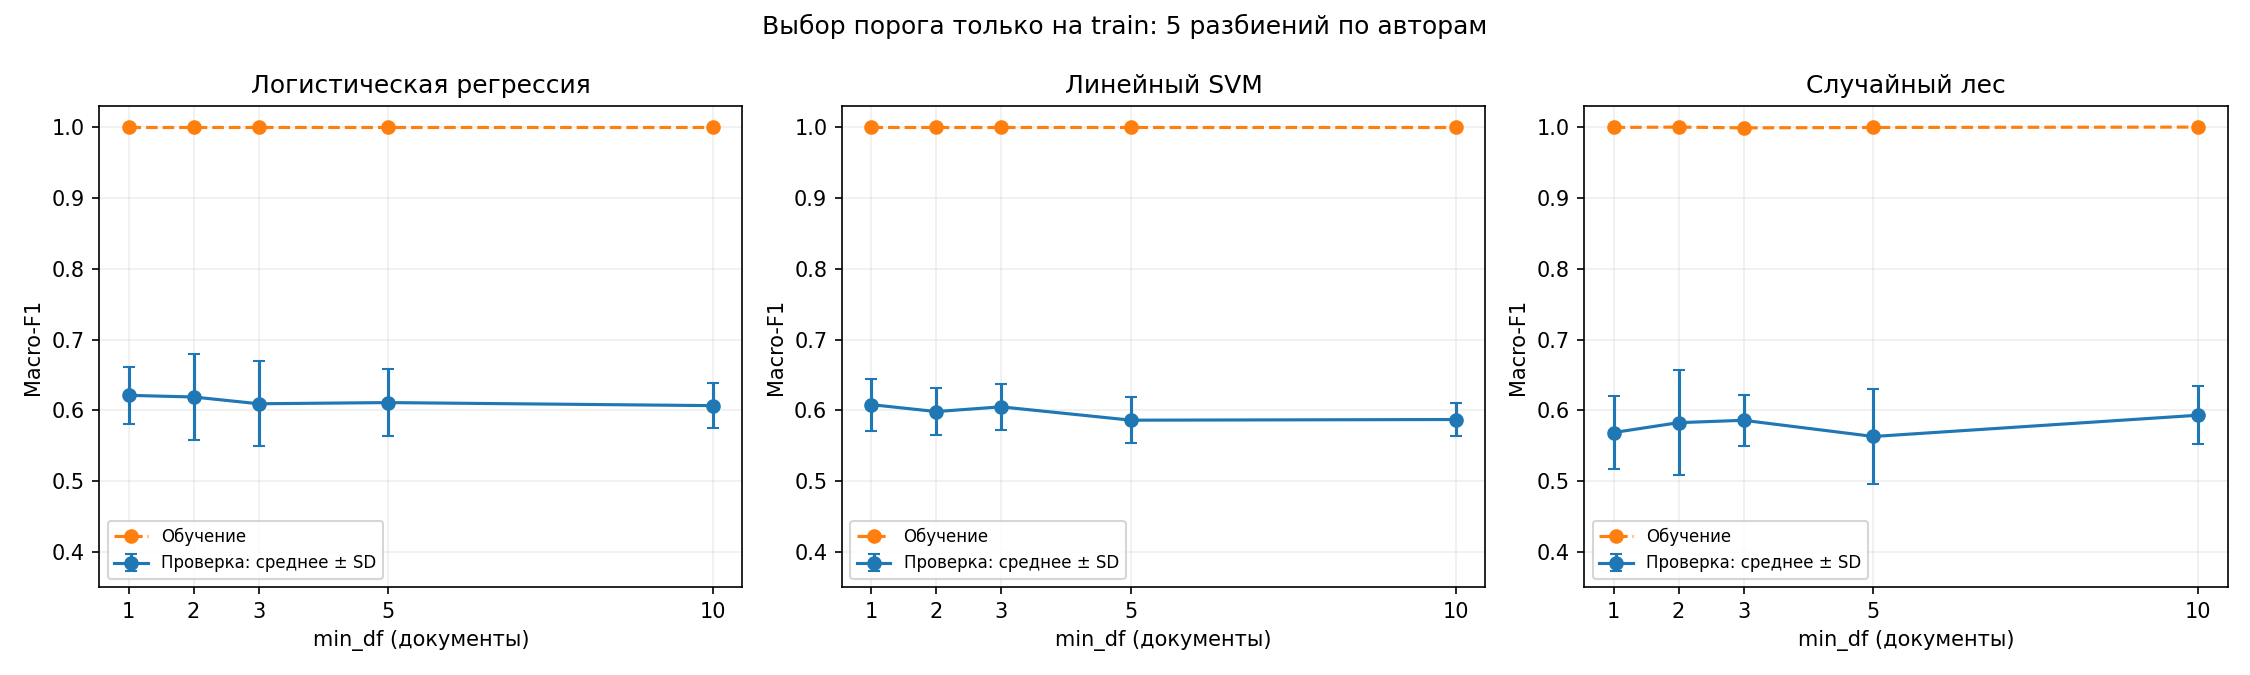

In [3]:
display(min_df_result["cv_summary"].round(4))
display(min_df_result["selection"].round(4))
display(Image(filename=str(min_df_ROOT / "reports/figures/cv_min_df.png")))

Полосы на графике показывают стандартное отклонение по пяти folds, а не доверительный интервал. Для логистической регрессии и SVM максимум CV остался при `min_df=1`. Варианты 2 и 3 нужны для сравнения фильтрации, но не объявляются лучшими по тесту.

#### 4. Метрики на общем тесте и размер словаря

,model,variant,min_df,vocabulary_size,cv_macro_f1,train_macro_f1,test_macro_f1,test_accuracy,test_precision_humor,test_recall_humor,test_f1_humor,test_roc_auc,train_test_gap
0,logreg,baseline,1,17342,0.6212,1.0,0.6111,0.632,0.5102,0.5319,0.5208,0.7158,0.3889
1,logreg,filtered,2,9617,0.6188,1.0,0.6449,0.664,0.5510,0.5745,0.5625,0.7139,0.3551
2,linear_svm,baseline,1,17342,0.6081,1.0,0.6560,0.680,0.5778,0.5532,0.5652,0.7267,0.3440
3,linear_svm,filtered,3,6854,0.6050,1.0,0.6859,0.704,0.6042,0.6170,0.6105,0.7158,0.3141
4,random_forest,baseline,1,17342,0.5687,1.0,0.5967,0.672,0.6250,0.3191,0.4225,0.6995,0.4033
5,random_forest,filtered,10,2458,0.5931,1.0,0.5969,0.664,0.5926,0.3404,0.4324,0.6798,0.4031


,min_df,vocabulary_size,removed_terms,removed_fraction
0,1,17342,0,0.0000
1,2,9617,7725,0.4455
2,3,6854,10488,0.6048
3,5,4518,12824,0.7395
4,10,2458,14884,0.8583


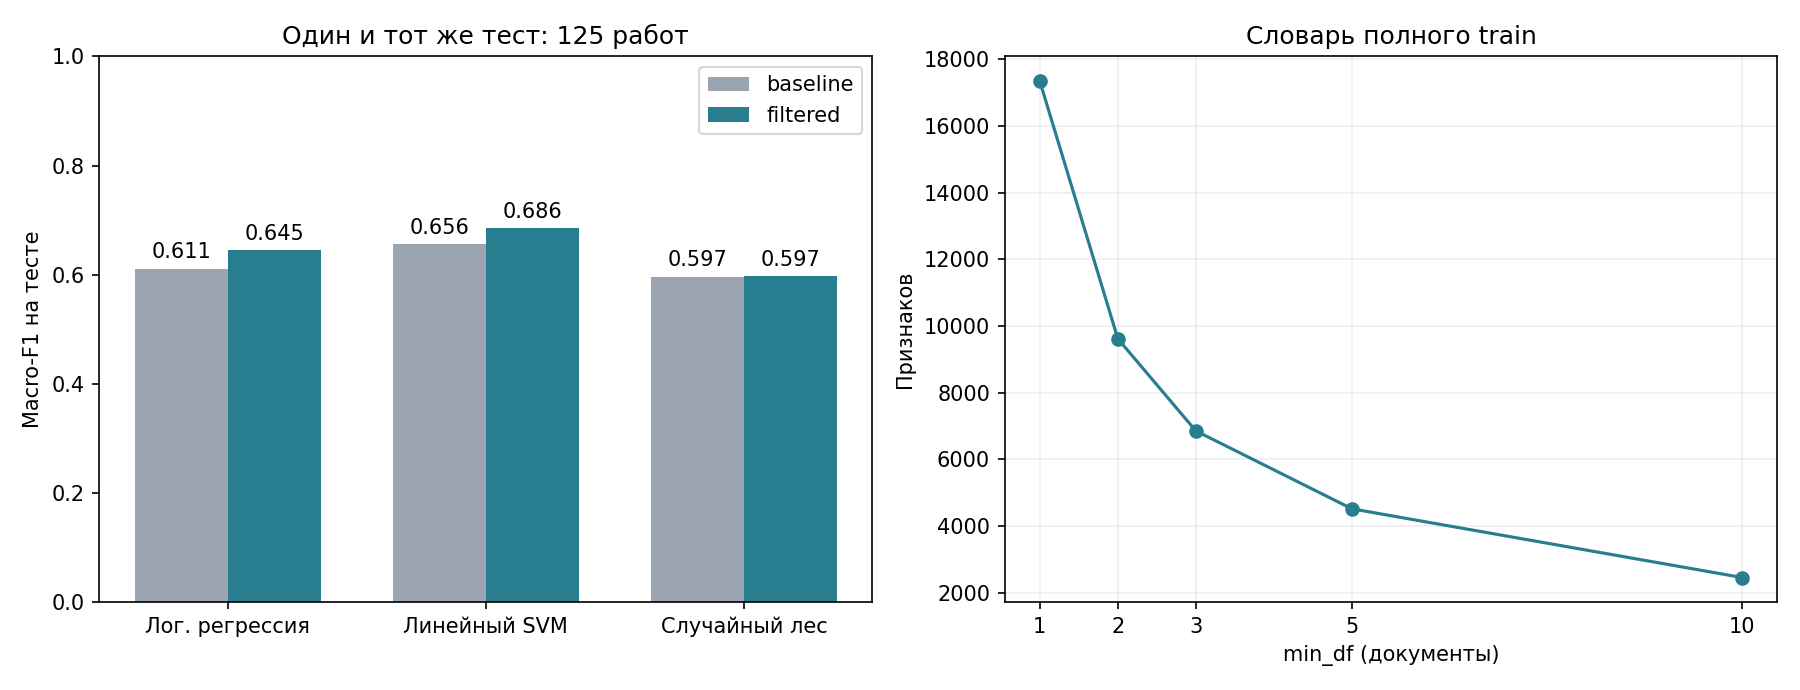

In [4]:
min_df_metrics = min_df_result["metrics"]
min_df_columns = ["model", "variant", "min_df", "vocabulary_size", "cv_macro_f1",
           "train_macro_f1", "test_macro_f1", "test_accuracy", "test_precision_humor",
           "test_recall_humor", "test_f1_humor", "test_roc_auc", "train_test_gap"]
display(min_df_metrics[min_df_columns].round(4))
display(min_df_result["vocabulary"].round(4))
display(Image(filename=str(min_df_ROOT / "reports/figures/comparison.png")))

In [5]:
min_df_delta_rows = []
for min_df_name, min_df_group in min_df_metrics.groupby("model", sort=False):
    min_df_rows = min_df_group.set_index("variant")
    min_df_before, min_df_after = min_df_rows.loc["baseline"], min_df_rows.loc["filtered"]
    min_df_delta_rows.append({
        "Модель": min_df_name,
        "Изменение Macro-F1": min_df_after.test_macro_f1 - min_df_before.test_macro_f1,
        "Изменение ROC-AUC": min_df_after.test_roc_auc - min_df_before.test_roc_auc,
        "Сокращение словаря, %": 100 * (1 - min_df_after.vocabulary_size / min_df_before.vocabulary_size),
    })
display(pd.DataFrame(min_df_delta_rows).round(4))
print("Базовая модель: всегда Ангст")
display(pd.Series(min_df_result["run"]["dummy_test"]).round(4))

Базовая модель: всегда Ангст


,Модель,Изменение Macro-F1,Изменение ROC-AUC,"Сокращение словаря, %"
0,logreg,0.0338,-0.0019,44.5450
1,linear_svm,0.0299,-0.0109,60.4775
2,random_forest,0.0002,-0.0198,85.8263


accuracy           0.6240
precision_humor    0.0000
recall_humor       0.0000
f1_humor           0.0000
macro_f1           0.3842
roc_auc            0.5000
dtype: float64

#### 5. Выводы и ограничения

В выполненном запуске:

- Логистическая регрессия: min_df=2 сокращает словарь до 9 617 признаков, Macro-F1 теста растёт с 0,6111 до 0,6449.
- SVM: min_df=3 сокращает словарь до 6 854, Macro-F1 растёт с 0,6560 до 0,6859.
- Случайный лес: min_df=10 оставляет 2 458 признаков, Macro-F1 практически не меняется: 0,5967 → 0,5969; Accuracy и ROC-AUC снижаются.

**Переобучение не устранено:** train Macro-F1 = 1,0 у всех шести вариантов. CV предпочитает min_df=1 для линейных моделей и 10 для леса. Рост тестового Macro-F1 у линейных моделей не даёт основания изменить выбор по CV; ROC-AUC после фильтрации у них снизился.

Малый тест из 125 работ уже использовался в исходной лабораторной. Подбор не обращается к нему, однако это повторный анализ существующего holdout. Различия не проверялись на статистическую значимость. Авторские группы защищают от пересечения одинаковых URL, но не от псевдонимов, соавторства и близких переписываний. Источник меток — теги карточек, а не независимая экспертная разметка.

В старом выводе было 17 343 признака, при текущем запуске — 17 342. Перенесённая предобработка совпала с исполненными исходными ячейками на текущем CSV для всех 616 текстов и ID разбиения; причина отличия от исторического вывода не подтверждена без версий прежней среды и хеша прежнего файла. Здесь baseline и filtered рассчитаны на одной текущей среде.

Эти выводы относятся к зафиксированному запуску. После изменения данных или настроек их нужно пересмотреть, опираясь на новые таблицы. Подробный отчёт генерируется в `reports/results.md`.

#### 6. Проверки целостности результатов

In [6]:
assert len(min_df_metrics) == 6
assert min_df_result["run"]["author_overlap"] == 0
assert min_df_result["run"]["processed_text_overlap"] == 0
assert min_df_metrics[["train_zero_vectors", "test_zero_vectors"]].to_numpy().sum() == 0
for _, min_df_group in min_df_metrics.groupby("model"):
    min_df_pair = min_df_group.set_index("variant")
    assert min_df_pair.loc["filtered", "vocabulary_size"] < min_df_pair.loc["baseline", "vocabulary_size"]
    assert (min_df_group[["tn", "fp", "fn", "tp"]].sum(axis=1) == len(min_df_test)).all()
print("Проверки пройдены. Параметры и версии:")
display(pd.Series(min_df_result["run"]["versions"], name="Версия").to_frame())
print("SHA-256 корпуса:", min_df_result["run"]["provenance"]["dataset_sha256"])

Проверки пройдены. Параметры и версии:
SHA-256 корпуса: ab57291310bc5804d17bb58b4a12e2b6daf2d1aadef854bfba7e9c57a3bd825a


,Версия
numpy,2.2.6
pandas,2.2.3
scipy,1.15.3
scikit-learn,1.7.2
nltk,3.10.3
matplotlib,3.10.3


Документация: [CountVectorizer и min_df](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html), [предотвращение утечек](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

### 1.5. Лемматизация и сравнение со стеммингом

Сравниваем способы приведения слов к начальной форме; для основного варианта используем spaCy ru_core_news_sm и словарь исключений для имён и терминов мира Гарри Поттера. Классы и разбиение на обучение и тест сохраняем, чтобы оценивать изменения на одних и тех же работах.

#### Подключение и сравнение лемматизаторов

In [ ]:
# Дополнительные зависимости описаны в requirements.txt и README.
# Модель: python -m spacy download ru_core_news_sm

In [ ]:
import re
import simplemma
import spacy
import pymorphy3

from natasha import (
    Segmenter, MorphVocab, NewsEmbedding,
    NewsMorphTagger, Doc
)

sample_text = original  # тот же фрагмент, который мы уже смотрели

# Подготовка инструментов
morph_compare = pymorphy3.MorphAnalyzer()
nlp_spacy = spacy.load("ru_core_news_sm", disable=["parser", "ner"])

segmenter = Segmenter()
morph_vocab = MorphVocab()
embedding = NewsEmbedding()
morph_tagger = NewsMorphTagger(embedding)

# spaCy и Natasha обрабатывают целый фрагмент, сохраняя контекст
spacy_doc = nlp_spacy(sample_text)
spacy_lemmas = {
    token.idx: token.lemma_.lower()
    for token in spacy_doc if token.is_alpha
}

natasha_doc = Doc(sample_text)
natasha_doc.segment(segmenter)
natasha_doc.tag_morph(morph_tagger)
for token in natasha_doc.tokens:
    token.lemmatize(morph_vocab)

natasha_lemmas = {
    token.start: token.lemma.lower()
    for token in natasha_doc.tokens
    if token.text.isalpha() and token.lemma
}

# Сопоставляем результаты по месту слова в исходном тексте
rows = []
for match in list(re.finditer(r"[^\W\d_]+", sample_text))[:80]:
    word = match.group().lower()
    position = match.start()

    rows.append({
        "Исходное слово": word,
        "Стемминг": stemmer.stem(word),
        "pymorphy3": morph_compare.parse(word)[0].normal_form,
        "simplemma": simplemma.lemmatize(word, lang="ru"),
        "Natasha": natasha_lemmas.get(position, "—"),
        "spaCy": spacy_lemmas.get(position, "—"),
    })

lemma_comparison = pd.DataFrame(rows)

with pd.option_context("display.max_rows", None):
    display(lemma_comparison)

#### Лемматизация выбранным способом

In [ ]:
def spacy_lemmas(doc):
    result = []

    for token in doc:
        word = token.text.lower()

        if not word.isalpha() or word in stop_words_ru:
            continue

        if word in special_forms:
            lemma = special_forms[word]
        else:
            lemma = token.lemma_.lower() or word

        result.append(lemma)

    return result

spacy_docs = nlp_spacy.pipe(task["text"].tolist(), batch_size=16)
task["tokens_lemma_spacy"] = [
    spacy_lemmas(doc) for doc in spacy_docs
]
task["text_lemma_spacy"] = task["tokens_lemma_spacy"].map(" ".join)

train["text_lemma_spacy"] = task.loc[train.index, "text_lemma_spacy"]
test["text_lemma_spacy"] = task.loc[test.index, "text_lemma_spacy"]

print("Обработано работ:", len(task))
print("Пустых текстов:", task["text_lemma_spacy"].eq("").sum())
print("Медиана слов:", task["tokens_lemma_spacy"].map(len).median())

print("\nСтемминг:", task["text_stem"].iloc[0].split()[:25])
print("spaCy:    ", task["text_lemma_spacy"].iloc[0].split()[:25])

#### Сравнение словоформ и роли контекста

In [ ]:
from IPython.display import display, HTML
from html import escape

examples = task[
    task["rating"].astype(str).str.strip().str.upper().eq("G")
].sample(2, random_state=42)

for number, (_, row) in enumerate(examples.iterrows(), start=1):
    stem_text = escape(row["text_stem"])
    lemma_text = escape(row["text_lemma_spacy"])

    display(HTML(f"""
    <h3>Работа {number}</h3>
    <table style="width:100%; table-layout:fixed; border-collapse:collapse;">
      <tr>
        <th style="width:50%; padding:12px; text-align:left;">
  NLTK RussianStemmer (Snowball) + исключения
</th>
<th style="width:50%; padding:12px; text-align:left;">
  spaCy ru_core_news_sm + исключения
</th>
      </tr>
      <tr>
        <td style="padding:14px; vertical-align:top; line-height:1.6;
                   overflow-wrap:anywhere; border:1px solid #ccc;">
          {stem_text}
        </td>
        <td style="padding:14px; vertical-align:top; line-height:1.6;
                   overflow-wrap:anywhere; border:1px solid #ccc;">
          {lemma_text}
        </td>
      </tr>
    </table>
    """))

In [ ]:
# Показываем, зачем лемматизатору контекст

sentences = [
    "Она пила воду.",
    "Острая пила лежала на столе."
]

rows = []

for sentence in sentences:
    doc = nlp_spacy(sentence)

    for token in doc:
        if token.text.lower() == "пила":
            rows.append({
                "Предложение": sentence,
                "Слово": token.text,
                "NLTK Snowball": stem_with_exceptions(token.text.lower()),
                "spaCy ru_core_news_sm": token.lemma_,
                "Часть речи по spaCy": token.pos_,
            })

display(pd.DataFrame(rows))

In [ ]:
from razdel import sentenize
from IPython.display import display, HTML
from html import escape

examples = [
    ("019ee711-dea9-7ea5-8cc9-f8032149ec83", "ели", "ель", "многовековой ели"),
    ("01a0be24-20e8-7ca0-b520-796da297caef", "ели", "есть", "который они ели"),
    ("019f95d0-2139-7825-a492-5546219c20a5", "стали", "стать", "стали мужчинами"),
    ("01a10b46-d2a5-7873-b863-2113ccaa25cc", "стали", "сталь", "хваткой из стали"),
]

for story_id, word, expected, anchor in examples:
    row = hp.loc[hp["story_id"].astype(str).eq(story_id)].iloc[0]
    text = row["text"]

    # Находим нужное полное предложение
    sentence = next(
        s for s in sentenize(text)
        if anchor in s.text.lower()
    )

    # spaCy обрабатывает полный текст, как и в нашей основной ячейке
    doc = nlp_spacy(text)
    token = next(
        t for t in doc
        if t.text.lower() == word
        and sentence.start <= t.idx < sentence.stop
    )

    display(HTML(f"""
    <div style="padding:16px; margin:16px 0; border:1px solid #bbb;
                border-radius:8px; line-height:1.7;">
      <b>{escape(row["title"])}</b>
      <p style="font-size:17px; overflow-wrap:anywhere;">
        {escape(sentence.text)}
      </p>
      <div>
        Слово: <b>{escape(word)}</b> ·
        стемминг: <b>{escape(stem_with_exceptions(word))}</b> ·
        ожидаемая лемма: <b>{escape(expected)}</b> ·
        spaCy: <b>{escape(token.lemma_)}</b>
        ({escape(token.pos_)})
      </div>
    </div>
    """))

#### BoW по леммам и сравнение качества моделей

In [ ]:
# 1.5. Мешок слов из лемм spaCy

lemma_vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

X_train_lemma = lemma_vectorizer.fit_transform(train["text_lemma_spacy"])
X_test_lemma = lemma_vectorizer.transform(test["text_lemma_spacy"])

print("Стемминг — обучение:", X_train_bow.shape, "тест:", X_test_bow.shape)
print("spaCy — обучение:   ", X_train_lemma.shape, "тест:", X_test_lemma.shape)

In [ ]:
# 1.5. Сравнение стемминга и лемматизации spaCy

import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

models_for_comparison = {
    "Логистическая регрессия": LogisticRegression(
        C=1.0, class_weight="balanced",
        max_iter=2000, random_state=42
    ),
    "Линейный SVM": LinearSVC(
        C=1.0, class_weight="balanced", random_state=42
    ),
    "Случайный лес": RandomForestClassifier(
        n_estimators=100, min_samples_leaf=2,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

text_variants = {
    "NLTK Snowball + исключения": (X_train_bow, X_test_bow),
    "spaCy ru_core_news_sm + исключения": (X_train_lemma, X_test_lemma),
}

y_train = train["target"].astype(int)
y_test = test["target"].astype(int)

results = []

# Обучаем каждую модель отдельно на стемминге и на леммах
for text_name, (X_tr, X_te) in text_variants.items():
    for model_name, model_template in models_for_comparison.items():
        model = clone(model_template)
        model.fit(X_tr, y_train)

        predictions = model.predict(X_te)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_te)[:, 1]
        else:
            scores = model.decision_function(X_te)

        results.append({
            "Модель": model_name,
            "Обработка текста": text_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "F1 (Юмор)": f1_score(y_test, predictions, pos_label=1),
            "Macro-F1": f1_score(y_test, predictions, average="macro"),
            "ROC-AUC": roc_auc_score(y_test, scores),
        })

lemma_comparison = pd.DataFrame(results)

# Сортируем модели по их лучшему Macro-F1
model_order = (
    lemma_comparison.groupby("Модель")["Macro-F1"]
    .max()
    .sort_values(ascending=False)
    .index
)

model_rank = {name: i for i, name in enumerate(model_order)}
method_rank = {
    "NLTK Snowball + исключения": 0,
    "spaCy ru_core_news_sm + исключения": 1,
}

lemma_comparison["_model_rank"] = lemma_comparison["Модель"].map(model_rank)
lemma_comparison["_method_rank"] = (
    lemma_comparison["Обработка текста"].map(method_rank)
)

lemma_comparison = (
    lemma_comparison
    .sort_values(["_model_rank", "_method_rank"])
    .drop(columns=["_model_rank", "_method_rank"])
    .reset_index(drop=True)
)

display(lemma_comparison.round(3))

## Часть 2. TF-IDF

### 2.1. Собственный размеченный корпус

Вместо учебных файлов используем загруженный выше корпус: тексты, метки «Ангст» и «Юмор», а также авторские группы для разбиения.

### 2.2. Преобразование текстов в TF-IDF

In [ ]:
# 2.2. TF-IDF: словарь и веса учим только на обучающих работах

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train["text_stem"])
X_test_tfidf = tfidf_vectorizer.transform(test["text_stem"])

print("Обучение:", X_train_tfidf.shape)
print("Тест:", X_test_tfidf.shape)
print("Совпадает ли число работ с BoW:",
      X_train_tfidf.shape[0] == X_train_bow.shape[0]
      and X_test_tfidf.shape[0] == X_test_bow.shape[0])

#### Примеры весов обычных и редких слов

In [ ]:
# Пример: насколько «редки» слова в обучающих работах

example_words = [
    "гарри", "гермиона", "хогвартс",
    "квиддич", "патронус", "дементор"
]

rows = []

for word in example_words:
    if word in tfidf_vectorizer.vocabulary_:
        column = tfidf_vectorizer.vocabulary_[word]

        rows.append({
            "Слово": word,
            "В скольких работах встретилось":
                X_train_tfidf[:, column].getnnz(),
            "Из скольких работ": len(train),
            "IDF (вес редкости)":
                tfidf_vectorizer.idf_[column],
        })

idf_example = pd.DataFrame(rows).sort_values(
    "В скольких работах встретилось",
    ascending=False
)

display(idf_example.round(2))

In [ ]:
# Самые распространённые слова после очистки

word_stats = pd.DataFrame({
    "Слово": tfidf_vectorizer.get_feature_names_out(),
    "Работ со словом": X_train_tfidf.getnnz(axis=0),
    "IDF": tfidf_vectorizer.idf_,
})

word_stats["Доля работ, %"] = (
    100 * word_stats["Работ со словом"] / len(train)
)

most_common = word_stats.sort_values(
    "Работ со словом", ascending=False
).head(15)

display(
    most_common[
        ["Слово", "Работ со словом", "Доля работ, %", "IDF"]
    ].round(2)
)

### 2.3. Сравнение BoW и TF-IDF на тех же работах

In [ ]:
# 2.2–2.3. BoW против TF-IDF на одинаковых данных и моделях

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

representations = {
    "BoW": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
}

comparison_results = []

for method_name, (X_tr, X_te) in representations.items():
    for model_name, model_template in models_for_comparison.items():
        model = clone(model_template)
        model.fit(X_tr, y_train)

        predictions = model.predict(X_te)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_te)[:, 1]
        else:
            scores = model.decision_function(X_te)

        comparison_results.append({
            "Модель": model_name,
            "Представление": method_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision (Юмор)": precision_score(
                y_test, predictions, pos_label=1, zero_division=0
            ),
            "Recall (Юмор)": recall_score(
                y_test, predictions, pos_label=1, zero_division=0
            ),
            "F1 (Юмор)": f1_score(
                y_test, predictions, pos_label=1, zero_division=0
            ),
            "Macro-F1": f1_score(
                y_test, predictions, average="macro"
            ),
            "ROC-AUC": roc_auc_score(y_test, scores),
        })

bow_tfidf_comparison = pd.DataFrame(comparison_results)

# У каждой модели две строки подряд: BoW, затем TF-IDF
model_order = (
    bow_tfidf_comparison.groupby("Модель")["Macro-F1"]
    .max()
    .sort_values(ascending=False)
    .index
)

model_rank = {name: i for i, name in enumerate(model_order)}

bow_tfidf_comparison["_model_rank"] = (
    bow_tfidf_comparison["Модель"].map(model_rank)
)
bow_tfidf_comparison["_method_rank"] = (
    bow_tfidf_comparison["Представление"].map({"BoW": 0, "TF-IDF": 1})
)

bow_tfidf_comparison = (
    bow_tfidf_comparison
    .sort_values(["_model_rank", "_method_rank"])
    .drop(columns=["_model_rank", "_method_rank"])
    .reset_index(drop=True)
)

display(bow_tfidf_comparison.round(3))

#### ROC-кривые для двух представлений

In [ ]:
# 2.3. ROC-кривые: BoW против TF-IDF для каждой модели

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score

representations = {
    "BoW": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (model_name, model_template) in zip(
    axes, models_for_comparison.items()
):
    for method_name, (X_tr, X_te) in representations.items():
        model = clone(model_template)
        model.fit(X_tr, y_train)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_te)[:, 1]
        else:
            scores = model.decision_function(X_te)

        fpr, tpr, _ = roc_curve(y_test, scores)
        auc = roc_auc_score(y_test, scores)

        ax.plot(
            fpr, tpr, linewidth=2,
            label=f"{method_name} (AUC = {auc:.3f})"
        )

    ax.plot(
        [0, 1], [0, 1],
        "k--", alpha=0.6, label="Случайное угадывание"
    )
    ax.set_title(model_name)
    ax.set_xlabel("Доля ложных срабатываний")
    ax.set_ylabel("Доля найденного юмора")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("ROC-кривые: BoW и TF-IDF на одном тестовом наборе", fontsize=14)
plt.tight_layout()
plt.show()

## Часть 3. Векторные представления и части речи

### 3.1. Word2Vec: обучение и классификация

Модель слов обучается только на текстах обучающей выборки.

In [ ]:
# 3.1. Обучаем Word2Vec только на обучающих текстах

import numpy as np
from gensim.models import Word2Vec

train_words = train["text_stem"].str.split().tolist()
test_words = test["text_stem"].str.split().tolist()

w2v = Word2Vec(
    sentences=train_words,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=20,
    workers=1,
    seed=42
)

def document_vector(words, model):
    known = [model.wv[word] for word in words if word in model.wv]

    if known:
        return np.mean(known, axis=0)

    return np.zeros(model.vector_size, dtype=np.float32)

X_train_w2v = np.vstack([
    document_vector(words, w2v) for words in train_words
])
X_test_w2v = np.vstack([
    document_vector(words, w2v) for words in test_words
])

print("Слов в словаре Word2Vec:", len(w2v.wv))
print("Обучение: работы × координаты =", X_train_w2v.shape)
print("Тест: работы × координаты =", X_test_w2v.shape)
print("Пустых векторов на тесте:",
      (np.linalg.norm(X_test_w2v, axis=1) == 0).sum())

#### Близкие слова: примеры

In [ ]:
# Пример того, чему Word2Vec научился на наших текстах

example_words = ["гарри", "драко", "хогвартс"]

rows = []

for word in example_words:
    if word not in w2v.wv:
        continue

    for neighbour, similarity in w2v.wv.most_similar(word, topn=7):
        rows.append({
            "Исходное слово": word,
            "Близкое слово": neighbour,
            "Косинусное сходство": similarity,
        })

display(pd.DataFrame(rows).round(3))

#### Word2Vec без стемминга, со стеммингом и с леммами

In [ ]:
# 3.1. Word2Vec без стемминга и с лемматизацией

from gensim.models import Word2Vec
import numpy as np

plain_train_words = train["tokens_no_stop"].tolist()
plain_test_words = test["tokens_no_stop"].tolist()

lemma_train_words = train["text_lemma_spacy"].str.split().tolist()
lemma_test_words = test["text_lemma_spacy"].str.split().tolist()

w2v_settings = dict(
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=20,
    workers=1,
    seed=42
)

w2v_plain = Word2Vec(
    sentences=plain_train_words,
    **w2v_settings
)

w2v_lemma = Word2Vec(
    sentences=lemma_train_words,
    **w2v_settings
)

X_train_w2v_plain = np.vstack([
    document_vector(words, w2v_plain)
    for words in plain_train_words
])
X_test_w2v_plain = np.vstack([
    document_vector(words, w2v_plain)
    for words in plain_test_words
])

X_train_w2v_lemma = np.vstack([
    document_vector(words, w2v_lemma)
    for words in lemma_train_words
])
X_test_w2v_lemma = np.vstack([
    document_vector(words, w2v_lemma)
    for words in lemma_test_words
])

print("Словари Word2Vec:")
print("Без стемминга:", len(w2v_plain.wv))
print("Со стеммингом:", len(w2v.wv))
print("С лемматизацией:", len(w2v_lemma.wv))

print("\nРазмеры векторов работ:")
print("Без стемминга:", X_train_w2v_plain.shape, X_test_w2v_plain.shape)
print("Со стеммингом:", X_train_w2v.shape, X_test_w2v.shape)
print("С лемматизацией:", X_train_w2v_lemma.shape, X_test_w2v_lemma.shape)

#### Сравнение Word2Vec с BoW и TF-IDF

In [ ]:
# 3.1. Сравнение BoW, TF-IDF и трёх вариантов Word2Vec

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

w2v_variants = {
    "Word2Vec: без стемминга": (
        X_train_w2v_plain, X_test_w2v_plain
    ),
    "Word2Vec: стемминг": (
        X_train_w2v, X_test_w2v
    ),
    "Word2Vec: лемматизация": (
        X_train_w2v_lemma, X_test_w2v_lemma
    ),
}

w2v_results = []

for text_name, (X_tr, X_te) in w2v_variants.items():
    for model_name, model_template in models_for_comparison.items():

        if model_name == "Случайный лес":
            model = clone(model_template)
        else:
            model = make_pipeline(
                StandardScaler(),
                clone(model_template)
            )

        model.fit(X_tr, y_train)
        predictions = model.predict(X_te)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_te)[:, 1]
        else:
            scores = model.decision_function(X_te)

        w2v_results.append({
            "Модель": model_name,
            "Представление": text_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision (Юмор)": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall (Юмор)": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 (Юмор)": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Macro-F1": f1_score(
                y_test, predictions, average="macro"
            ),
            "ROC-AUC": roc_auc_score(y_test, scores),
        })

# Добавляем уже посчитанные BoW и TF-IDF
all_methods = pd.concat(
    [bow_tfidf_comparison, pd.DataFrame(w2v_results)],
    ignore_index=True
)

method_order = {
    "BoW": 0,
    "TF-IDF": 1,
    "Word2Vec: без стемминга": 2,
    "Word2Vec: стемминг": 3,
    "Word2Vec: лемматизация": 4,
}

model_order = (
    all_methods.groupby("Модель")["Macro-F1"]
    .max()
    .sort_values(ascending=False)
    .index
)
model_rank = {name: i for i, name in enumerate(model_order)}

all_methods["_model_rank"] = all_methods["Модель"].map(model_rank)
all_methods["_method_rank"] = (
    all_methods["Представление"].map(method_order)
)

all_methods = (
    all_methods
    .sort_values(["_model_rank", "_method_rank"])
    .drop(columns=["_model_rank", "_method_rank"])
    .reset_index(drop=True)
)

display(all_methods.round(3))

#### ROC-кривые для всех вариантов векторизации

In [ ]:
# 3.1. ROC-кривые для BoW, TF-IDF и трёх вариантов Word2Vec

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score

all_representations = {
    "BoW": (X_train_bow, X_test_bow, False),
    "TF-IDF": (X_train_tfidf, X_test_tfidf, False),
    "W2V без стемминга": (
        X_train_w2v_plain, X_test_w2v_plain, True
    ),
    "W2V со стеммингом": (
        X_train_w2v, X_test_w2v, True
    ),
    "W2V с леммами": (
        X_train_w2v_lemma, X_test_w2v_lemma, True
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (model_name, model_template) in zip(
    axes, models_for_comparison.items()
):
    for text_name, (X_tr, X_te, is_w2v) in all_representations.items():

        # Те же настройки, что в таблице результатов
        if is_w2v and model_name != "Случайный лес":
            model = make_pipeline(
                StandardScaler(),
                clone(model_template)
            )
        else:
            model = clone(model_template)

        model.fit(X_tr, y_train)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_te)[:, 1]
        else:
            scores = model.decision_function(X_te)

        fpr, tpr, _ = roc_curve(y_test, scores)
        auc = roc_auc_score(y_test, scores)

        ax.plot(
            fpr, tpr, linewidth=2,
            label=f"{text_name}: AUC = {auc:.3f}"
        )

    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(model_name)
    ax.set_xlabel("Доля ложных срабатываний")
    ax.set_ylabel("Доля найденного юмора")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle(
    "ROC-кривые: все способы представления текста",
    fontsize=15
)
plt.tight_layout()
plt.show()

### 3.2. Части речи: разметка, признаки и классификация

Сравниваем spaCy, Natasha и pymorphy3 на исходных текстах, затем представляем каждую работу долями частей речи.

#### Обозначения частей речи

| Обозначение | По-русски | Пример |
|---|---|---|
| `NOUN` | существительное | домов |
| `PROPN` | имя собственное | Лондона, Дурсли |
| `VERB` | глагол | живут |
| `ADJ` | прилагательное | престарелые |
| `ADV` | наречие | зачастую |
| `PRON` | местоимение | которые |
| `DET` | определительное слово | таких |
| `ADP` | предлог | в, от |
| `PART` | частица | не |
| `NUM` | числительное | одна |
| `CCONJ` | сочинительный союз | и, но |
| `SCONJ` | подчинительный союз | чтобы, если |

pymorphy3 использует другие обозначения: PREP — предлог (ADP), ADJF — прилагательное (ADJ), ADVB — наречие (ADV), INFN — неопределённая форма глагола (VERB), PRCL — частица (PART), CONJ — союз. Поэтому разные подписи не всегда означают несогласие библиотек.

#### Разметка трёх реальных фрагментов

In [ ]:
# 3.2. Сравнение разметки частей речи на 3 реальных отрывках

import pandas as pd
import pymorphy3

from natasha import Doc, Segmenter, NewsEmbedding, NewsMorphTagger
from IPython.display import display, HTML
from html import escape

# Подключаем разметчики
pymorphy_pos = pymorphy3.MorphAnalyzer()

natasha_segmenter = Segmenter()
natasha_embeddings = NewsEmbedding()
natasha_pos_tagger = NewsMorphTagger(natasha_embeddings)

# Берём 3 воспроизводимых примера с рейтингом G
pos_examples = task[
    task["rating"].astype(str).str.strip().str.upper().eq("G")
].sample(3, random_state=42)

for number, (_, row) in enumerate(pos_examples.iterrows(), start=1):
    snippet = row["text"][:600].rsplit(" ", 1)[0]

    # spaCy: часть речи с учётом контекста
    spacy_doc = nlp_spacy(snippet)

    # Natasha: часть речи с учётом контекста
    natasha_doc = Doc(snippet)
    natasha_doc.segment(natasha_segmenter)
    natasha_doc.tag_morph(natasha_pos_tagger)

    # Привязываем результаты Natasha к позициям слов в тексте
    natasha_by_position = {
        (token.start, token.stop): token.pos
        for token in natasha_doc.tokens
    }

    rows = []

    for token in spacy_doc:
        if not token.is_alpha:
            continue

        # pymorphy3 разбирает слово отдельно, без предложения;
        # берём первый (наиболее вероятный) вариант
        pymorphy_parse = pymorphy_pos.parse(token.text)[0]

        rows.append({
            "Слово": token.text,
            "spaCy": token.pos_,
            "Natasha": natasha_by_position.get(
                (token.idx, token.idx + len(token.text)),
                "—"
            ),
            "pymorphy3": pymorphy_parse.tag.POS or "—",
        })

    display(HTML(f"""
        <h3>Пример {number}:
  <a href="{escape(str(row['source_url']), quote=True)}" target="_blank">
    {escape(str(row['title']))}
  </a>
</h3>
        <div style="white-space:pre-wrap; line-height:1.6;
                    padding:14px; border:1px solid #ccc;">
            {escape(snippet)}
        </div>
    """))

    with pd.option_context(
        "display.max_rows", 100,
        "display.max_colwidth", None
    ):
        display(pd.DataFrame(rows).head(60))

#### Доли частей речи как признаки произведения

In [ ]:
# 3.2. Доли частей речи по spaCy, Natasha и pymorphy3

import numpy as np
from collections import Counter
from functools import lru_cache
from nltk.tokenize import wordpunct_tokenize
from natasha import Doc

pos_groups = [
    "NOUN", "VERB", "ADJ", "ADV", "PRON",
    "ADP", "CONJ", "PART", "NUM", "INTJ", "OTHER"
]

def common_pos(tag):
    """Приводим обозначения spaCy/Natasha к общим группам."""
    replacements = {
        "PROPN": "NOUN",
        "AUX": "VERB",
        "DET": "PRON",
        "CCONJ": "CONJ",
        "SCONJ": "CONJ",
    }
    group = replacements.get(tag, tag)
    return group if group in pos_groups else "OTHER"

def pymorphy_common_pos(tag):
    """Переводим обозначения pymorphy3 в те же группы."""
    replacements = {
        "NOUN": "NOUN",
        "VERB": "VERB",
        "INFN": "VERB",
        "PRTF": "VERB",
        "PRTS": "VERB",
        "GRND": "VERB",
        "ADJF": "ADJ",
        "ADJS": "ADJ",
        "COMP": "ADJ",
        "ADVB": "ADV",
        "PRED": "ADV",
        "NPRO": "PRON",
        "PREP": "ADP",
        "CONJ": "CONJ",
        "PRCL": "PART",
        "NUMR": "NUM",
        "INTJ": "INTJ",
    }
    return replacements.get(tag, "OTHER")

def pos_proportions(tags):
    counts = Counter(tags)
    total = sum(counts.values())
    return [
        counts.get(group, 0) / total if total else 0
        for group in pos_groups
    ]

@lru_cache(maxsize=50000)
def pymorphy_tag(word):
    return pymorphy_pos.parse(word)[0].tag.POS

def spacy_pos_vectors(texts):
    vectors = []
    for doc in nlp_spacy.pipe(texts, batch_size=16):
        tags = [
            common_pos(token.pos_)
            for token in doc
            if token.is_alpha
        ]
        vectors.append(pos_proportions(tags))
    return np.asarray(vectors)

def natasha_pos_vectors(texts):
    vectors = []
    for text in texts:
        doc = Doc(text)
        doc.segment(natasha_segmenter)
        doc.tag_morph(natasha_pos_tagger)

        tags = [
            common_pos(token.pos)
            for token in doc.tokens
            if token.text.isalpha()
        ]
        vectors.append(pos_proportions(tags))
    return np.asarray(vectors)

def pymorphy_pos_vectors(texts):
    vectors = []
    for text in texts:
        tags = [
            pymorphy_common_pos(pymorphy_tag(word.lower()))
            for word in wordpunct_tokenize(text)
            if word.isalpha()
        ]
        vectors.append(pos_proportions(tags))
    return np.asarray(vectors)

train_texts = train["text"].fillna("").astype(str).tolist()
test_texts = test["text"].fillna("").astype(str).tolist()

print("Обрабатываем spaCy...")
X_train_pos_spacy = spacy_pos_vectors(train_texts)
X_test_pos_spacy = spacy_pos_vectors(test_texts)

print("Обрабатываем Natasha...")
X_train_pos_natasha = natasha_pos_vectors(train_texts)
X_test_pos_natasha = natasha_pos_vectors(test_texts)

print("Обрабатываем pymorphy3...")
X_train_pos_pymorphy = pymorphy_pos_vectors(train_texts)
X_test_pos_pymorphy = pymorphy_pos_vectors(test_texts)

print("\nРазмеры матриц (работы × группы частей речи):")
print("spaCy:    ", X_train_pos_spacy.shape, X_test_pos_spacy.shape)
print("Natasha:  ", X_train_pos_natasha.shape, X_test_pos_natasha.shape)
print("pymorphy3:", X_train_pos_pymorphy.shape, X_test_pos_pymorphy.shape)

#### Описательное сравнение жанров

In [ ]:
# 3.2. Средние доли частей речи в обучающих работах

pos_names_ru = {
    "NOUN": "Существительные и имена",
    "VERB": "Глаголы",
    "ADJ": "Прилагательные",
    "ADV": "Наречия",
    "PRON": "Местоимения",
    "ADP": "Предлоги",
    "CONJ": "Союзы",
    "PART": "Частицы",
    "NUM": "Числительные",
    "INTJ": "Междометия",
    "OTHER": "Прочее",
}

train_pos_variants = {
    "spaCy": X_train_pos_spacy,
    "Natasha": X_train_pos_natasha,
    "pymorphy3": X_train_pos_pymorphy,
}

rows = []

for method_name, matrix in train_pos_variants.items():
    pos_df = pd.DataFrame(matrix, columns=pos_groups)
    pos_df["Класс"] = y_train.to_numpy()

    means = pos_df.groupby("Класс")[pos_groups].mean() * 100

    for tag in pos_groups:
        angst_share = means.loc[0, tag]
        humor_share = means.loc[1, tag]

        rows.append({
            "Разметчик": method_name,
            "Часть речи": pos_names_ru[tag],
            "Ангст, %": angst_share,
            "Юмор, %": humor_share,
        })

pos_shares = pd.DataFrame(rows)

with pd.option_context("display.max_rows", 100):
    display(pos_shares.round(2))

#### Круговые диаграммы

In [ ]:
# 3.2. Крупные круговые диаграммы с подписями у секторов

import matplotlib.pyplot as plt

main_tags = [
    "NOUN", "VERB", "ADJ", "ADV",
    "PRON", "ADP", "CONJ"
]
other_tags = ["PART", "NUM", "INTJ", "OTHER"]

short_names = {
    "NOUN": "Существ.",
    "VERB": "Глаголы",
    "ADJ": "Прилаг.",
    "ADV": "Наречия",
    "PRON": "Местоим.",
    "ADP": "Предлоги",
    "CONJ": "Союзы",
}

colors = plt.get_cmap("tab10").colors[:8]

for method in ["spaCy", "Natasha", "pymorphy3"]:
    method_data = (
        pos_shares[pos_shares["Разметчик"].eq(method)]
        .set_index("Часть речи")
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(17, 7), constrained_layout=True
    )

    for ax, (class_name, column) in zip(axes, [
        ("Ангст", "Ангст, %"),
        ("Юмор", "Юмор, %"),
    ]):
        values = [
            method_data.loc[pos_names_ru[tag], column]
            for tag in main_tags
        ]
        values.append(sum(
            method_data.loc[pos_names_ru[tag], column]
            for tag in other_tags
        ))

        names = [short_names[tag] for tag in main_tags] + ["Остальное"]
        labels = [
            f"{name}\n{value:.1f}%"
            for name, value in zip(names, values)
        ]

        ax.pie(
            values,
            labels=labels,
            colors=colors,
            startangle=90,
            counterclock=False,
            labeldistance=1.12,
            textprops={"fontsize": 11},
            wedgeprops={"edgecolor": "white", "linewidth": 1},
        )
        ax.set_title(class_name, fontsize=15)
        ax.axis("equal")

    fig.suptitle(
        f"Части речи по {method}",
        fontsize=17
    )
    plt.show()

#### Классификация по долям частей речи

In [ ]:
# 3.2. Классификация по частям речи: сравнение на тесте

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

pos_variants = {
    "spaCy": (X_train_pos_spacy, X_test_pos_spacy),
    "Natasha": (X_train_pos_natasha, X_test_pos_natasha),
    "pymorphy3": (X_train_pos_pymorphy, X_test_pos_pymorphy),
}

pos_results = []

for tagger_name, (X_tr, X_te) in pos_variants.items():
    for model_name, model_template in models_for_comparison.items():

        if model_name == "Случайный лес":
            model = clone(model_template)
        else:
            # Масштабирование обучается только на train
            model = make_pipeline(
                StandardScaler(),
                clone(model_template)
            )

        model.fit(X_tr, y_train)
        predictions = model.predict(X_te)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_te)[:, 1]
        else:
            scores = model.decision_function(X_te)

        pos_results.append({
            "Модель": model_name,
            "Разметчик": tagger_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision (Юмор)": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall (Юмор)": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 (Юмор)": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Macro-F1": f1_score(
                y_test, predictions, average="macro"
            ),
            "ROC-AUC": roc_auc_score(y_test, scores),
        })

pos_comparison = (
    pd.DataFrame(pos_results)
    .sort_values(
        ["Macro-F1", "ROC-AUC"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(pos_comparison.round(3))

### 3.3. Сводное сравнение всех методов

Сводим результаты моделей и представлений в одну таблицу и сортируем по Macro-F1.

In [ ]:
# 3.3. Общее сравнение всех методов лабораторной

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# В старой таблице для BoW на леммах не было Precision/Recall.
# Досчитываем только эти три модели с теми же настройками.
lemma_full_rows = []

for model_name, model_template in models_for_comparison.items():
    model = clone(model_template)
    model.fit(X_train_lemma, y_train)

    predictions = model.predict(X_test_lemma)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_lemma)[:, 1]
    else:
        scores = model.decision_function(X_test_lemma)

    lemma_full_rows.append({
        "Модель": model_name,
        "Представление": "BoW: лемматизация",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Юмор)": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall (Юмор)": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 (Юмор)": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "ROC-AUC": roc_auc_score(y_test, scores),
    })

lemma_full = pd.DataFrame(lemma_full_rows)

# Уже полученные результаты BoW и TF-IDF
bow_tfidf_final = bow_tfidf_comparison.copy()
bow_tfidf_final["Представление"] = (
    bow_tfidf_final["Представление"].replace({
        "BoW": "BoW: стемминг",
        "TF-IDF": "TF-IDF: стемминг",
    })
)

# Уже полученные результаты Word2Vec
w2v_final = pd.DataFrame(w2v_results).copy()

# Уже полученные результаты частей речи
pos_final = pos_comparison.rename(
    columns={"Разметчик": "Представление"}
).copy()
pos_final["Представление"] = (
    "Части речи: " + pos_final["Представление"]
)

result_columns = [
    "Модель", "Представление", "Accuracy",
    "Precision (Юмор)", "Recall (Юмор)",
    "F1 (Юмор)", "Macro-F1", "ROC-AUC"
]

final_comparison = (
    pd.concat(
        [bow_tfidf_final, lemma_full, w2v_final, pos_final],
        ignore_index=True
    )[result_columns]
    .sort_values(
        ["Macro-F1", "ROC-AUC"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("Всего сочетаний метода и модели:", len(final_comparison))

with pd.option_context("display.max_rows", 40):
    display(final_comparison.round(3))